# GNAL · Full training with HF checkpoint backup
Your public dataset and revision are configured. Enable Kaggle **GPU T4 ×2** and **Internet**, then run cells in order.

Default: **paper**, 20 warmup + 100 main epochs, random initialization, one fold and 20% label budget. Implementation assumptions remain below. DataLoader workers default to zero to avoid the earlier worker cleanup errors.

Every completed epoch is uploaded as its own full resumable checkpoint to **aee4/gnal-training-checkpoints**, under `paper-fold0-20pct`. A live HTML table shows the epoch metrics and cloud-backup status. Every epoch is retained; full optimizer checkpoints can occupy tens of GB across 120 epochs, and uploads add runtime. HF account storage limits still apply.

Supply your HF write token as Kaggle secret **HF_TOKEN**, or through the hidden prompt. A new model repo is private by default; an existing repo keeps its visibility. Tokens are not written into checkpoints or notebook outputs.

After a session reset, rerun this notebook with the same repo, RUN_ID and configuration: it downloads the latest successfully uploaded epoch and resumes automatically. An interrupted epoch must be repeated. A checkpoint is remote only after **HF BACKUP CONFIRMED** appears. Backup failure stops training rather than silently continuing without protection. Run only one training session per RUN_ID.


In [1]:
%pip -q install "datasets>=3,<5" "huggingface_hub>=0.27,<2" "PyYAML>=6"


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
WORK = Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd() / 'gnal_work'
WORK.mkdir(parents=True, exist_ok=True)
(WORK / 'gnal_hf.py').write_text('"""Independent GNAL implementation. See README for assumptions, not official code."""\nimport argparse, json, math, os, random, time, warnings, hashlib\nfrom tqdm.auto import tqdm\nfrom dataclasses import dataclass, asdict\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\nimport torch\nfrom torch import nn\nimport torch.nn.functional as F\nfrom torch.utils.data import Dataset, DataLoader, WeightedRandomSampler\nfrom torchvision import transforms as T, models\nfrom sklearn.model_selection import StratifiedGroupKFold, train_test_split\nfrom sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score\n\nCLASSES = [\'AKIEC\', \'BCC\', \'BKL\', \'DF\', \'MEL\', \'NV\', \'VASC\']\n@dataclass\nclass Config:\n    data_root: str = \'/kaggle/input\'\n    prepared_manifest: str = \'\'\n    metadata_csv: str = \'\'\n    labels_csv: str = \'\'\n    output: str = \'/kaggle/working/gnal_run\'\n    seed: int = 42\n    fold: int = 0\n    label_ratio: float = .2\n    warmup_epochs: int = 20\n    epochs: int = 100\n    batch_size: int = 12\n    unlabeled_ratio: int = 1\n    workers: int = 2\n    image_size: int = 224\n    lr: float = .001\n    lambda_n: float = .5\n    lambda_g: float = .4\n    eta: float = .3\n    temperature: float = .1\n    neighbor_threshold: float = .8\n    max_neighbors: int = 32\n    context_limit: int = 96\n    gamma: float = 1.\n    beta: float = .1\n    confidence: float = .95\n    hidden: int = 256\n    pretrained: bool = False\n    imagenet_normalize: bool = False\n    amp: bool = True\n    ablation: str = \'full\'  # full, no_ncfr, no_rega, supervised\n    max_steps: int = 0\n    resume: str = \'\'\n    tiny: bool = False  # synthetic smoke tests only\n    device: str = \'cuda\' if torch.cuda.is_available() else \'cpu\'\n\n\ndef seed_all(seed):\n    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)\n    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)\n\n\ndef discover_data(c):\n    root = Path(c.data_root)\n    csvs = sorted(root.rglob(\'*.csv\'))\n    metadata = Path(c.metadata_csv) if c.metadata_csv else None\n    labels = Path(c.labels_csv) if c.labels_csv else None\n    if metadata is None:\n        candidates = []\n        for p in csvs:\n            try:\n                cols = pd.read_csv(p, nrows=1).columns\n                if \'lesion_id\' in cols and (\'image_id\' in cols or \'image\' in cols): candidates.append(p)\n            except Exception: pass\n        if len(candidates) != 1:\n            raise ValueError(f\'Found {len(candidates)} lesion metadata CSVs. Set metadata_csv explicitly. Candidates: {candidates}\')\n        metadata = candidates[0]\n    df = pd.read_csv(metadata).rename(columns={\'image\':\'image_id\'})\n    if not {\'lesion_id\', \'image_id\'}.issubset(df.columns):\n        raise ValueError(\'Metadata must contain image_id (or image) AND lesion_id. Add HAM10000_metadata.csv; image-only splitting is deliberately disabled.\')\n    df[\'image_id\'] = df.image_id.astype(str).map(lambda x: Path(x).stem)\n    if \'dx\' in df.columns:\n        df[\'class\'] = df.dx.astype(str).str.upper()\n    else:\n        if labels is None:\n            hits = []\n            for p in csvs:\n                cols = pd.read_csv(p, nrows=1).columns\n                if set(CLASSES).issubset(cols): hits.append(p)\n            if len(hits) != 1: raise ValueError(f\'Set labels_csv explicitly. Candidates: {hits}\')\n            labels = hits[0]\n        lab = pd.read_csv(labels).rename(columns={\'image\':\'image_id\'})\n        lab[\'image_id\'] = lab.image_id.astype(str).map(lambda x: Path(x).stem)\n        vals = lab[CLASSES].to_numpy(float)\n        if not (np.isin(vals, [0,1]).all() and (vals.sum(1)==1).all()):\n            raise ValueError(\'Expected one-hot ground truth, exactly one class per row.\')\n        lab[\'class\'] = np.array(CLASSES)[vals.argmax(1)]\n        df = df.merge(lab[[\'image_id\',\'class\']], on=\'image_id\', how=\'left\', validate=\'one_to_one\')\n        if df[\'class\'].isna().any(): raise ValueError(\'Some metadata images have no corresponding ground-truth labels.\')\n    if df.image_id.duplicated().any() or df.lesion_id.isna().any():\n        raise ValueError(\'Duplicate image IDs or missing lesion IDs.\')\n    if not set(df[\'class\']).issubset(CLASSES): raise ValueError(\'Unknown class labels.\')\n    if (df.groupby(\'lesion_id\')[\'class\'].nunique() > 1).any(): raise ValueError(\'A lesion has conflicting diagnoses.\')\n    images = {}; duplicate_copies = 0\n    def digest(path):\n        h=hashlib.sha256()\n        with open(path,\'rb\') as f:\n            for block in iter(lambda:f.read(1024*1024),b\'\'): h.update(block)\n        return h.digest()\n    for p in sorted(root.rglob(\'*\')):\n        if p.suffix.lower() in (\'.jpg\',\'.jpeg\',\'.png\'):\n            if p.stem in images:\n                previous=Path(images[p.stem])\n                if previous.stat().st_size!=p.stat().st_size or digest(previous)!=digest(p):\n                    raise ValueError(f\'Conflicting image copies for {p.stem}; attach one dataset copy only.\')\n                duplicate_copies+=1\n                continue\n            images[p.stem] = str(p)\n    if duplicate_copies: print(\'Ignored byte-identical duplicate image copies:\',duplicate_copies)\n    df[\'path\'] = df.image_id.map(images)\n    if df.path.isna().any(): raise ValueError(f\'Missing images: {df.loc[df.path.isna(), "image_id"].head().tolist()}\')\n    df[\'target\'] = df[\'class\'].map({x:i for i,x in enumerate(CLASSES)})\n    print(\'Data:\', len(df), \'images;\', df.lesion_id.nunique(), \'lesions;\', metadata)\n    if len(df) != 10015: warnings.warn(\'Paper uses 10,015 images; this dataset has a different size.\')\n    return df.reset_index(drop=True)\n\n\ndef make_splits(df, c):\n    if not 0 < c.label_ratio < 1: raise ValueError(\'label_ratio must be between 0 and 1.\')\n    if not 0 <= c.fold < 5: raise ValueError(\'fold must be 0..4\')\n    outer = StratifiedGroupKFold(5, shuffle=True, random_state=c.seed)\n    trval, test = list(outer.split(df, df.target, df.lesion_id))[c.fold]\n    pool = df.iloc[trval]\n    # One of eight inner folds = ~10% total validation; outer test = ~20%.\n    inner = StratifiedGroupKFold(8, shuffle=True, random_state=c.seed+1)\n    tri, vai = next(inner.split(pool, pool.target, pool.lesion_id))\n    train, val, test = pool.iloc[tri].copy(), pool.iloc[vai].copy(), df.iloc[test].copy()\n    for a,b in [(train,val),(train,test),(val,test)]:\n        assert not set(a.lesion_id) & set(b.lesion_id)\n    # Label complete lesions to avoid one labelled view effectively labelling another hidden view.\n    groups = train.groupby(\'lesion_id\').target.first().reset_index()\n    if groups.target.value_counts().min() < 2: raise ValueError(\'Too few lesions per class to select labelled data.\')\n    chosen, _ = train_test_split(groups, train_size=c.label_ratio, stratify=groups.target, random_state=c.seed+2)\n    train[\'labeled\'] = train.lesion_id.isin(chosen.lesion_id)\n    train = train.reset_index(drop=True)\n    if train.loc[train.labeled,\'target\'].nunique() != 7: raise ValueError(\'Labelled set must contain all seven classes.\')\n    val[\'labeled\'] = False; test[\'labeled\'] = False\n    train[\'split\']=\'train\'; val[\'split\']=\'validation\'; test[\'split\']=\'test\'\n    manifest = pd.concat([train,val,test], ignore_index=True)\n    manifest.to_csv(Path(c.output)/\'split_manifest.csv\', index=False)\n    print(\'Split sizes:\', len(train), len(val), len(test), \'; labelled training images:\', train.labeled.sum())\n    return train, val.reset_index(drop=True), test.reset_index(drop=True)\n\n\ndef transform(c, kind):\n    ops = [T.Resize((c.image_size,c.image_size))]\n    if kind != \'eval\': ops += [T.RandomHorizontalFlip(), T.RandomRotation(20)]\n    if kind == \'strong\': ops += [T.RandAugment(num_ops=2, magnitude=9)]\n    ops += [T.ToTensor()]\n    if c.imagenet_normalize: ops += [T.Normalize([.485,.456,.406],[.229,.224,.225])]\n    return T.Compose(ops)\n\nclass Lesions(Dataset):\n    def __init__(self, frame, c, kind=\'eval\', hide=False):\n        self.df=frame; self.weak=transform(c,kind); self.strong=transform(c,\'strong\'); self.kind=kind; self.hide=hide\n    def __len__(self): return len(self.df)\n    def __getitem__(self,i):\n        r=self.df.iloc[i]\n        with Image.open(r.path) as im: im=im.convert(\'RGB\')\n        x=self.weak(im)\n        return x, self.strong(im) if self.kind==\'unlabeled\' else x, (-1 if self.hide else int(r.target)), int(r.name)\n\nclass Encoder(nn.Module):\n    def __init__(self,c):\n        super().__init__()\n        if c.tiny:\n            self.net=nn.Sequential(nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(1),nn.Flatten())\n            self.dim=16\n        else:\n            m=models.resnet50(weights=models.ResNet50_Weights.DEFAULT if c.pretrained else None)\n            self.dim=m.fc.in_features; m.fc=nn.Identity(); self.net=m\n    def forward(self,x): return self.net(x)\n\nclass GNAL(nn.Module):\n    def __init__(self,c):\n        super().__init__(); self.encoder=Encoder(c); d=self.encoder.dim\n        self.head=nn.Linear(d,7); self.g1=nn.Linear(d,c.hidden,bias=False); self.g2=nn.Linear(c.hidden,7,bias=False)\n    def graph(self,z,a):\n        # Works with [nodes,d] or batched [batch,nodes,d].\n        return a @ self.g2(F.relu(a @ self.g1(z)))\n\n\ndef normalize_adj(a):\n    a=a+torch.eye(a.shape[-1],device=a.device)\n    inv=a.sum(-1).clamp_min(1e-8).rsqrt()\n    return inv[..., :, None]*a*inv[...,None,:]\n\n\ndef neighbor_query(z, bank, ids, c):\n    logits=F.normalize(z.float(),dim=-1) @ bank.T / c.temperature\n    logits[torch.arange(len(z),device=z.device),ids]=-float(\'inf\')\n    width=min(c.max_neighbors or len(bank)-1,len(bank)-1)\n    values, indices=logits.detach().topk(width,dim=1)\n    mask=(values-values[:,:1]).exp() >= c.neighbor_threshold\n    return [set(row[keep].cpu().tolist()) for row,keep in zip(indices,mask)], logits\n\n@torch.no_grad()\ndef refresh_neighbors(bank,c):\n    result=[]\n    for start in tqdm(range(0,len(bank),128),desc=\'Refreshing neighborhoods\',unit=\'chunk\',leave=False):\n        ids=torch.arange(start,min(start+128,len(bank)),device=bank.device)\n        ns,_=neighbor_query(bank[ids],bank,ids,c); result.extend(ns)\n    return result\n\ndef jaccard(a,b): return len(a & b)/max(1,len(a | b))\n\ndef graph_adjacency(node_ids, neighborhoods, labeled, device):\n    n=len(node_ids); a=np.zeros((n,n),np.float32)\n    for i,u in enumerate(node_ids):\n        for j,v in enumerate(node_ids):\n            if i!=j and (v in neighborhoods[u] or u in neighborhoods[v]):\n                a[i,j]=1. if labeled[u] and labeled[v] else jaccard(neighborhoods[u], neighborhoods[v])\n    return torch.tensor(a,device=device)\n\ndef ncfr_loss(ids, logits, neighborhoods, labeled):\n    terms=[]; lp=logits.log_softmax(1)\n    for row,i in enumerate(ids.tolist()):\n        if labeled[i]: continue\n        ns=sorted(neighborhoods[i])\n        if ns:\n            w=torch.tensor([jaccard(neighborhoods[i],neighborhoods[j]) for j in ns],device=logits.device)\n            terms.append(-(w*lp[row,ns]).mean())\n    return torch.stack(terms).mean() if terms else logits[torch.isfinite(logits)].sum()*0\n\n\ndef graph_train(model,z,ids,bank,neighbors,labeled,known_y,c,augment):\n    z=F.normalize(z.float(),dim=1)\n    unique, inverse=torch.unique(ids,sorted=True,return_inverse=True)\n    # Weighted sampling may repeat images. Preserve one graph node per image; average their live features.\n    live=torch.zeros((len(unique),z.shape[1]),device=z.device,dtype=z.dtype).index_add(0,inverse,z)\n    counts=torch.bincount(inverse,minlength=len(unique)).to(z.dtype)\n    live=live/counts[:,None]\n    active=unique.tolist(); used=set(active)\n    contexts=sorted(set().union(*(neighbors[i] for i in active))-used)\n    if len(contexts)>c.context_limit:\n        # Deterministic ranking by aggregate similarity to current batch.\n        ctx=torch.tensor(contexts,device=z.device)\n        ranks=(bank[ctx] @ F.normalize(live.detach().float(),dim=1).T).amax(1)\n        contexts=ctx[ranks.topk(c.context_limit).indices].tolist()\n    nodes=active+contexts\n    features=torch.cat([live.float(),bank[contexts]],0)\n    a=graph_adjacency(nodes,neighbors,labeled,z.device)\n    h=model.graph(features,normalize_adj(a)); hp=h.softmax(-1)\n    idx_l=[j for j,i in enumerate(active) if labeled[i]]\n    idx_u=[j for j,i in enumerate(active) if not labeled[i]]\n    gl=F.cross_entropy(h[idx_l],known_y[unique[idx_l]])\n    lg=h.sum()*0\n    if augment and idx_u:\n        number=max(1,math.ceil(c.eta*len(idx_u))) if c.eta>0 else 0\n        picks=random.sample(idx_u,min(number,len(idx_u)))\n        if picks:\n            li=torch.tensor(random.choices(idx_l,k=len(picks)),device=z.device)\n            ui=torch.tensor(picks,device=z.device)\n            sub=[]\n            for j,i in enumerate(nodes):\n                positions=[k for k,v in enumerate(nodes) if v in neighbors[i]]+[j]\n                sub.append(features[positions].mean(0))\n            sub=torch.stack(sub)\n            theta0=.5*torch.exp(-c.gamma*(sub[li]-sub[ui]).square().sum(1))\n            entropy=-(hp.detach()*hp.detach().clamp_min(1e-8).log()).sum(1)\n            theta=(theta0+c.beta*(entropy[li]-entropy[ui])/math.log(7)).clamp(0,1).detach()\n            mixed=theta[:,None]*features[li]+(1-theta[:,None])*features[ui]\n            aug_a=torch.zeros((len(nodes)+len(picks),)*2,device=z.device); aug_a[:len(nodes),:len(nodes)]=a\n            for q,(l,u) in enumerate(zip(li.tolist(),ui.tolist())):\n                # New node inherits union of parent neighborhoods and links to both parents.\n                connected=((a[l]>0)|(a[u]>0)).float(); connected[l]=1; connected[u]=1\n                aug_a[len(nodes)+q,:len(nodes)]=connected\n                aug_a[:len(nodes),len(nodes)+q]=connected\n            final=model.graph(torch.cat([features,mixed]),normalize_adj(aug_a))\n            target=theta[:,None]*F.one_hot(known_y[unique[li]],7).float()+(1-theta[:,None])*final[ui].detach().softmax(-1)\n            lg=-(target*final[len(nodes):].log_softmax(-1)).sum(1).mean()\n            gl=F.cross_entropy(final[idx_l],known_y[unique[idx_l]])\n    return gl,lg\n\n\ndef loader(frame,c,kind,balanced=False,hide=False):\n    ds=Lesions(frame,c,kind,hide)\n    sampler=None\n    if balanced:\n        counts=frame.target.value_counts()\n        sampler=WeightedRandomSampler([1/counts[y] for y in frame.target],len(frame),replacement=True)\n    return DataLoader(ds,batch_size=c.batch_size*(c.unlabeled_ratio if hide else 1),sampler=sampler,\n                      shuffle=(kind!=\'eval\' and sampler is None),num_workers=c.workers,pin_memory=c.device.startswith(\'cuda\'),drop_last=False)\n\ndef endlessly(dl):\n    while True:\n        yield from dl\n\n@torch.no_grad()\ndef fill_bank(model,dl,bank,c):\n    model.eval()\n    for x,_,_,ids in tqdm(dl,desc=\'Updating feature memory\',unit=\'batch\',leave=False):\n        bank[ids.to(c.device)]=F.normalize(model.encoder(x.to(c.device)).float(),dim=1)\n\n@torch.no_grad()\ndef predict(model,dl,bank,neighbors,labeled,c):\n    """Each held-out query uses its own training-only context, never another held-out sample."""\n    model.eval(); ys=[]; probs=[]; image_ids=[]\n    for x,_,y,ids in tqdm(dl,desc=\'Evaluating images\',unit=\'batch\',leave=False):\n        z=model.encoder(x.to(c.device)).float()\n        if c.ablation==\'supervised\': p=model.head(z).softmax(-1)\n        else:\n            logits=F.normalize(z,dim=1) @ bank.T/c.temperature\n            width=min(c.max_neighbors or len(bank),len(bank))\n            vals, ni=logits.topk(width,dim=1)\n            ps=[]\n            for q in range(len(z)):\n                ctx=ni[q][(vals[q]-vals[q,0]).exp()>=c.neighbor_threshold].tolist()\n                ctx=ctx[:c.context_limit]\n                features=torch.cat([F.normalize(z[q:q+1],dim=1),bank[ctx]])\n                a=torch.zeros((len(ctx)+1,)*2,device=c.device)\n                a[1:,1:]=graph_adjacency(ctx,neighbors,labeled,c.device)\n                # Query receives messages from training nodes, no messages back into reference context.\n                a[0,1:]=1.\n                ps.append(model.graph(features,normalize_adj(a))[0].softmax(-1))\n            p=torch.stack(ps)\n        ys.extend(y.tolist()); probs.extend(p.cpu().tolist()); image_ids.extend(ids.tolist())\n    return np.array(ys),np.array(probs),image_ids\n\n\ndef metrics(y,p):\n    pred=p.argmax(1); cm=confusion_matrix(y,pred,labels=range(7))\n    tp=cm.diagonal(); fn=cm.sum(1)-tp; fp=cm.sum(0)-tp; tn=cm.sum()-tp-fn-fp\n    result={\'accuracy\':float(accuracy_score(y,pred)), \'macro_f1\':float(f1_score(y,pred,labels=range(7),average=\'macro\',zero_division=0)),\n            \'macro_sensitivity\':float(np.mean(tp/np.maximum(tp+fn,1))), \'macro_specificity\':float(np.mean(tn/np.maximum(tn+fp,1)))}\n    try: result[\'macro_auc\']=float(roc_auc_score(y,p,multi_class=\'ovr\',labels=range(7),average=\'macro\'))\n    except ValueError: result[\'macro_auc\']=None\n    onehot=np.eye(7)[y]; result[\'brier_multiclass\']=float(np.square(p-onehot).sum(1).mean())\n    conf=p.max(1); correct=(pred==y); ece=0.\n    for lo,hi in zip(np.linspace(0,1,16)[:-1],np.linspace(0,1,16)[1:]):\n        mask=(conf>lo)&(conf<=hi)\n        if mask.any(): ece+=mask.mean()*abs(correct[mask].mean()-conf[mask].mean())\n    result[\'ece_toplabel_15bins\']=float(ece)\n    return result,cm\n\n\ndef save_plots(out,history,y,p):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc\n    if history:\n        h=pd.DataFrame(history); fig,ax=plt.subplots(1,2,figsize=(11,4))\n        ax[0].plot(h.epoch,h.loss); ax[0].set(title=\'Training loss\',xlabel=\'Epoch\')\n        ax[1].plot(h.epoch,h.val_macro_f1,label=\'Validation macro F1\'); ax[1].plot(h.epoch,h.val_accuracy,label=\'Validation accuracy\'); ax[1].legend()\n        fig.tight_layout(); fig.savefig(out/\'training_curves.png\',dpi=160); plt.close(fig)\n    _,cm=metrics(y,p); fig,ax=plt.subplots(figsize=(8,7)); ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,colorbar=False)\n    fig.tight_layout(); fig.savefig(out/\'confusion_matrix.png\',dpi=160); plt.close(fig)\n    fig,ax=plt.subplots(figsize=(7,6))\n    for j,name in enumerate(CLASSES):\n        if len(np.unique(y==j))==2:\n            fpr,tpr,_=roc_curve(y==j,p[:,j]); ax.plot(fpr,tpr,label=f\'{name}: {auc(fpr,tpr):.3f}\')\n    ax.plot([0,1],[0,1],\'k--\'); ax.set(xlabel=\'False positive rate\',ylabel=\'True positive rate\',title=\'Test one-vs-rest ROC\'); ax.legend()\n    fig.tight_layout(); fig.savefig(out/\'roc_curves.png\',dpi=160); plt.close(fig)\n\n\ndef run(c):\n    if c.temperature<=0 or not 0<c.neighbor_threshold<=1: raise ValueError(\'Invalid temperature or neighbor threshold.\')\n    if c.context_limit<1: raise ValueError(\'context_limit must be positive\')\n    if c.ablation not in [\'full\',\'no_ncfr\',\'no_rega\',\'supervised\']: raise ValueError(\'Invalid ablation\')\n    if c.pretrained and not c.imagenet_normalize: warnings.warn(\'ImageNet weights normally use imagenet_normalize=True.\')\n    seed_all(c.seed); out=Path(c.output); out.mkdir(parents=True,exist_ok=True)\n    if (out/\'last.pt\').exists() and not c.resume:\n        raise FileExistsError(\'Output already contains a run. Set resume to last.pt or choose a new output directory.\')\n    resume=None\n    if c.resume:\n        resume=torch.load(c.resume,map_location=\'cpu\',weights_only=False)\n        old=resume[\'config\']\n        for key in asdict(c):\n            if key not in [\'resume\',\'output\',\'workers\',\'device\',\'epochs\',\'max_steps\',\'amp\',\'data_root\',\'metadata_csv\',\'labels_csv\',\'prepared_manifest\'] and old[key]!=getattr(c,key):\n                raise ValueError(f\'Resume config mismatch: {key}\')\n    (out/\'config.json\').write_text(json.dumps(asdict(c),indent=2))\n    import torchvision, sklearn, platform\n    environment={\'python\':platform.python_version(),\'torch\':torch.__version__,\'torchvision\':torchvision.__version__,\n                 \'numpy\':np.__version__,\'pandas\':pd.__version__,\'sklearn\':sklearn.__version__,\n                 \'cuda\':torch.version.cuda,\'gpu\':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}\n    (out/\'environment.json\').write_text(json.dumps(environment,indent=2))\n    if c.prepared_manifest:\n        from hf_data import validate_manifest\n        prepared=Path(c.prepared_manifest)\n        info=json.loads(prepared.with_name(\'preparation.json\').read_text())\n        for key in [\'seed\',\'fold\',\'label_ratio\']:\n            if info[key]!=getattr(c,key): raise ValueError(\'Prepared dataset config mismatch: \'+key)\n        if info[\'classes\']!=CLASSES: raise ValueError(\'Class ordering mismatch\')\n        frame=validate_manifest(pd.read_csv(prepared))\n        frame.to_csv(out/\'split_manifest.csv\',index=False)\n        train=frame[frame.split==\'train\'].reset_index(drop=True)\n        val=frame[frame.split==\'validation\'].reset_index(drop=True)\n        test=frame[frame.split==\'test\'].reset_index(drop=True)\n    else:\n        df=discover_data(c); train,val,test=make_splits(df,c)\n    if resume and resume[\'train_ids\']!=train.image_id.tolist(): raise ValueError(\'Resume split/data order mismatch.\')\n    # Runtime target table contains -1 for all unlabelled images.\n    labeled=train.labeled.to_numpy(); known_y=torch.tensor(np.where(labeled,train.target,-1),device=c.device)\n    labeled_dl=loader(train[train.labeled],c,\'weak\',balanced=True)\n    unlabeled_dl=loader(train[~train.labeled],c,\'unlabeled\',hide=True)\n    bank_dl=loader(train,c,\'eval\'); val_dl=loader(val,c,\'eval\'); test_dl=loader(test,c,\'eval\')\n    model=GNAL(c).to(c.device)\n    opt=torch.optim.Adam(model.parameters(),lr=c.lr)\n    scheduler=torch.optim.lr_scheduler.StepLR(opt,step_size=20,gamma=.1)\n    enabled=c.amp and c.device.startswith(\'cuda\')\n    scaler=torch.amp.GradScaler(\'cuda\',enabled=enabled)\n    bank=torch.zeros((len(train),model.encoder.dim),device=c.device)\n    start=0; best=-1.; history=[]\n    if resume:\n        model.load_state_dict(resume[\'model\']); opt.load_state_dict(resume[\'optimizer\']); scheduler.load_state_dict(resume[\'scheduler\'])\n        scaler.load_state_dict(resume[\'scaler\']); start=resume[\'epoch\']+1; best=resume[\'best\']; history=resume[\'history\']\n        random.setstate(resume[\'python_rng\']); np.random.set_state(resume[\'numpy_rng\']); torch.set_rng_state(resume[\'torch_rng\'])\n        if torch.cuda.is_available() and resume[\'cuda_rng\'] is not None: torch.cuda.set_rng_state_all(resume[\'cuda_rng\'])\n    print(\'Initializing training-only feature memory...\',flush=True)\n    fill_bank(model,bank_dl,bank,c); neighbors=refresh_neighbors(bank,c)\n    total=c.warmup_epochs+c.epochs\n    print(\'Device:\',c.device,\'; visible GPUs:\',torch.cuda.device_count(),\'; using one GPU intentionally\')\n    for epoch in range(start,total):\n        began=time.time(); warm=epoch<c.warmup_epochs\n        ul=endlessly(unlabeled_dl); ll=endlessly(labeled_dl)\n        steps=len(labeled_dl) if warm or c.ablation==\'supervised\' else max(len(labeled_dl),len(unlabeled_dl))\n        if c.max_steps: steps=min(steps,c.max_steps)\n        model.train(); sums=np.zeros(5); accepted=0.; u_count=0\n        print(f\'Epoch {epoch+1}/{total} | {"warmup" if warm else "main training"} | {steps} batches\',flush=True)\n        progress=tqdm(range(steps),desc=f\'Epoch {epoch+1}/{total}\',unit=\'batch\')\n        for step in progress:\n            xl,_,yl,il=next(ll); xl=xl.to(c.device); yl=yl.to(c.device); il=il.to(c.device)\n            use_u=not warm and c.ablation!=\'supervised\'\n            if use_u:\n                xu,xs,_,iu=next(ul); xu=xu.to(c.device); xs=xs.to(c.device); iu=iu.to(c.device)\n                images=torch.cat([xl,xu,xs]); ids=torch.cat([il,iu])\n            else: images=xl; ids=il\n            opt.zero_grad(set_to_none=True)\n            with torch.autocast(device_type=torch.device(c.device).type,enabled=enabled):\n                feats=model.encoder(images); logits=model.head(feats)\n                base=F.cross_entropy(logits[:len(xl)],yl); unsup=base*0\n                if use_u:\n                    nu=len(xu); weak=logits[len(xl):len(xl)+nu]; strong=logits[-nu:]\n                    conf,pseudo=weak.detach().softmax(-1).max(-1); mask=conf>=c.confidence\n                    unsup=(F.cross_entropy(strong,pseudo,reduction=\'none\')*mask).mean()\n                    accepted+=mask.sum().item(); u_count+=nu\n                    z=feats[:len(xl)+nu]\n                else: z=feats\n            # Global similarity and graph operations stay FP32 for numerical stability.\n            with torch.autocast(device_type=torch.device(c.device).type,enabled=False):\n                z=z.float(); current,sim=neighbor_query(z,bank,ids,c)\n                for i,ns in zip(ids.tolist(),current): neighbors[i]=ns\n                if c.ablation==\'supervised\': gl=base.float(); ln=z.sum()*0; lg=ln\n                else:\n                    gl,lg=graph_train(model,z,ids,bank,neighbors,labeled,known_y,c,use_u and c.ablation!=\'no_rega\')\n                    ln=ncfr_loss(ids,sim,neighbors,labeled) if use_u and c.ablation!=\'no_ncfr\' else z.sum()*0\n                loss=.5*(base.float()+gl)+unsup.float()+c.lambda_n*ln+c.lambda_g*lg\n            if not torch.isfinite(loss): raise FloatingPointError(\'Non-finite loss; checkpoint from previous epoch is retained.\')\n            scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(),5.)\n            scaler.step(opt); scaler.update()\n            with torch.no_grad():\n                # Average duplicate entries deterministically.\n                unique,inv=torch.unique(ids,return_inverse=True)\n                emb=torch.zeros((len(unique),z.shape[1]),device=c.device).index_add_(0,inv,z.detach())\n                bank[unique]=F.normalize(emb,dim=1)\n            sums+=np.array([loss.item(),base.item(),unsup.item(),ln.item(),lg.item()])\n            progress.set_postfix(loss=f\'{loss.item():.4f}\',ncfr=f\'{ln.item():.4f}\',graph=f\'{lg.item():.4f}\',refresh=(step%10==0))\n        scheduler.step()\n        # Synchronize reference bank with current encoder before validation and checkpointing.\n        fill_bank(model,bank_dl,bank,c); neighbors=refresh_neighbors(bank,c)\n        print(\'Checking validation performance...\',flush=True)\n        vy,vp,_=predict(model,val_dl,bank,neighbors,labeled,c); vm,_=metrics(vy,vp)\n        row=dict(epoch=epoch+1,stage=\'warmup\' if warm else \'main\',seconds=time.time()-began,loss=sums[0]/steps,\n                 base=sums[1]/steps,unsupervised=sums[2]/steps,ncfr=sums[3]/steps,graph=sums[4]/steps,\n                 pseudo_acceptance=accepted/max(u_count,1),val_macro_f1=vm[\'macro_f1\'],val_accuracy=vm[\'accuracy\'],lr=opt.param_groups[0][\'lr\'])\n        history.append(row); pd.DataFrame(history).to_csv(out/\'history.csv\',index=False)\n        # Select only main-training epochs for a GNAL best model; warmup cannot win against main stage.\n        eligible=not warm or c.epochs==0\n        improved=eligible and vm[\'macro_f1\']>best\n        if improved: best=vm[\'macro_f1\']\n        state=dict(model=model.state_dict(),optimizer=opt.state_dict(),scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),epoch=epoch,\n                   best=best,history=history,config=asdict(c),train_ids=train.image_id.tolist(),classes=CLASSES,\n                   python_rng=random.getstate(),numpy_rng=np.random.get_state(),torch_rng=torch.get_rng_state(),\n                   cuda_rng=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)\n        torch.save(state,out/\'last.tmp\'); os.replace(out/\'last.tmp\',out/\'last.pt\')\n        if improved: torch.save(state,out/\'best.pt\')\n        callback=globals().get(\'CHECKPOINT_CALLBACK\')\n        if callback is None: raise RuntimeError(\'Cloud backup is not configured. Run the HF backup setup cell first.\')\n        callback(out,epoch+1,improved,history)\n    # Never inspect test metrics during training or use them for checkpoint selection.\n    if not (out/\'best.pt\').exists():\n        if c.resume and Path(c.resume).with_name(\'best.pt\').exists():\n            best_path=Path(c.resume).with_name(\'best.pt\')\n        else: raise RuntimeError(\'No best checkpoint here. Copy best.pt alongside last.pt when resuming to a new output directory.\')\n    else: best_path=out/\'best.pt\'\n    selected=torch.load(best_path,map_location=c.device,weights_only=False); model.load_state_dict(selected[\'model\'])\n    fill_bank(model,bank_dl,bank,c); neighbors=refresh_neighbors(bank,c)\n    print(\'Evaluating the selected checkpoint on the held-out test split...\',flush=True)\n    y,p,indices=predict(model,test_dl,bank,neighbors,labeled,c)\n    result,cm=metrics(y,p); result[\'best_epoch\']=selected[\'epoch\']+1\n    (out/\'test_metrics.json\').write_text(json.dumps(result,indent=2))\n    report=classification_report(y,p.argmax(1),labels=range(7),target_names=CLASSES,zero_division=0,output_dict=True)\n    pd.DataFrame(report).T.to_csv(out/\'classification_report.csv\')\n    pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(out/\'confusion_matrix.csv\')\n    pred=pd.DataFrame(p,columns=[\'prob_\'+n for n in CLASSES]); pred.insert(0,\'image_id\',test.iloc[indices].image_id.to_numpy())\n    pred[\'true_class\']=np.array(CLASSES)[y]; pred[\'predicted_class\']=np.array(CLASSES)[p.argmax(1)]; pred.to_csv(out/\'test_predictions.csv\',index=False)\n    save_plots(out,history,y,p); print(\'TEST (held out):\',json.dumps(result,indent=2))\n    return result\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser(); ap.add_argument(\'--config\',required=True)\n    args=ap.parse_args(); run(Config(**json.loads(Path(args.config).read_text())))\n')
import sys
sys.path.insert(0, str(WORK))
from pathlib import Path
WORK = Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd() / 'gnal_work'
WORK.mkdir(parents=True, exist_ok=True)
(WORK / 'hf_data.py').write_text('"""Hugging Face transport for a prepared GNAL dataset; no token is stored."""\nimport hashlib, io, json, re\nfrom tqdm.auto import tqdm\nfrom pathlib import Path\nimport pandas as pd\nimport numpy as np\nfrom PIL import Image as PILImage\nfrom datasets import Dataset, DatasetDict, Features, Value, Image as HFImage\nfrom huggingface_hub import HfApi, hf_hub_download\n\nCLASSES = [\'AKIEC\',\'BCC\',\'BKL\',\'DF\',\'MEL\',\'NV\',\'VASC\']\nFEATURES = Features({\'image\':HFImage(decode=False),\'image_id\':Value(\'string\'),\n    \'lesion_id\':Value(\'string\'),\'class_name\':Value(\'string\'),\'target\':Value(\'int64\'),\n    \'labeled\':Value(\'bool\'),\'sha256\':Value(\'string\')})\n\ndef validate_manifest(frame, require_paths=True):\n    f=frame.copy()\n    required={\'image_id\',\'lesion_id\',\'target\',\'labeled\',\'split\'}\n    if require_paths: required.add(\'path\')\n    if not required.issubset(f.columns): raise ValueError(f\'Missing columns: {required-set(f.columns)}\')\n    if f[list(required)].isna().any().any(): raise ValueError(\'Missing manifest values\')\n    if set(f.split)!= {\'train\',\'validation\',\'test\'}: raise ValueError(\'Expected three splits\')\n    if f.image_id.duplicated().any(): raise ValueError(\'Duplicate image IDs across splits\')\n    if f.groupby(\'lesion_id\').split.nunique().max()!=1: raise ValueError(\'Lesion leakage between splits\')\n    if f.groupby(\'lesion_id\').target.nunique().max()!=1: raise ValueError(\'Inconsistent lesion diagnoses\')\n    if not set(f.target.astype(int)).issubset(range(7)): raise ValueError(\'Invalid class IDs\')\n    vals=f.labeled.astype(str).str.lower()\n    if not vals.isin([\'true\',\'false\']).all(): raise ValueError(\'labeled must be boolean\')\n    f[\'labeled\']=vals.eq(\'true\')\n    if f.loc[f.split!=\'train\',\'labeled\'].any(): raise ValueError(\'Held-out rows cannot be training-labelled\')\n    tr=f[f.split==\'train\']\n    if tr.groupby(\'lesion_id\').labeled.nunique().max()!=1: raise ValueError(\'Label flag differs among views of a lesion\')\n    if tr.loc[tr.labeled,\'target\'].nunique()!=7 or (~tr.labeled).sum()==0: raise ValueError(\'Need labelled samples of all seven classes and unlabelled samples\')\n    if require_paths and not f.path.map(lambda p:Path(p).is_file()).all(): raise ValueError(\'Some prepared images are missing\')\n    return f\n\n\ndef build_dataset(manifest, destination, resize_to=224):\n    """Keep source images untouched; export RGB JPEG copies or original bytes."""\n    frame=validate_manifest(manifest); dest=Path(destination); dest.mkdir(parents=True,exist_ok=True)\n    groups={}\n    for split in [\'train\',\'validation\',\'test\']:\n        rows=[]\n        for r in frame[frame.split==split].itertuples():\n            if not re.fullmatch(r\'[A-Za-z0-9_-]+\',str(r.image_id)): raise ValueError(\'Unsafe image ID\')\n            if resize_to:\n                path=dest/(r.image_id+\'.jpg\')\n                with PILImage.open(r.path) as im:\n                    im.convert(\'RGB\').resize((resize_to,resize_to),PILImage.Resampling.BILINEAR).save(path,\'JPEG\',quality=95)\n            else:\n                path=Path(r.path)\n                with PILImage.open(path) as im: im.verify()\n            digest=hashlib.sha256(path.read_bytes()).hexdigest()\n            rows.append({\'image\':{\'path\':str(path),\'bytes\':None},\'image_id\':r.image_id,\n                         \'lesion_id\':str(r.lesion_id),\'class_name\':CLASSES[int(r.target)],\n                         \'target\':int(r.target),\'labeled\':bool(r.labeled),\'sha256\':digest})\n        groups[split]=Dataset.from_list(rows,features=FEATURES)\n    return DatasetDict(groups)\n\n\ndef dataset_card(info):\n    return \'\'\'---\nlicense: cc-by-nc-4.0\ntask_categories:\n- image-classification\nlanguage:\n- en\ntags:\n- medical\n- skin-lesion\n- semi-supervised\n- ham10000\n---\n# HAM10000: prepared GNAL experiment\n\nThis is a third-party preparation of HAM10000 / ISIC 2018 Task 3 for an independent GNAL implementation. It is not an official split or the GNAL author\'s release. Research/education experiment, not a clinical diagnostic service.\n\n## Original data and attribution\nHAM10000 Dataset: (c) ViDIR Group, Department of Dermatology, Medical University of Vienna. Original dataset: https://doi.org/10.7910/DVN/DBW86T .\nTschandl, P., Rosendahl, C. & Kittler, H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. Scientific Data 5, 180161 (2018). https://doi.org/10.1038/sdata.2018.161 .\nISIC challenge: Codella et al., Skin Lesion Analysis Toward Melanoma Detection 2018: A Challenge Hosted by the International Skin Imaging Collaboration. https://arxiv.org/abs/1902.03368 .\nOriginal data terms: https://challenge.isic-archive.com/data/ . Dataset license: CC BY-NC 4.0, https://creativecommons.org/licenses/by-nc/4.0/ . Original attribution and noncommercial restriction remain applicable. This preparation claims no ownership of the original images.\n\n## Changes made\nImages are \'\'\'+(\'RGB-resized to \'+str(info[\'resize_to\'])+\' square pixels and JPEG-encoded at quality 95.\' if info[\'resize_to\'] else \'stored as original image bytes without resizing.\')+\'\'\'\nMetadata is reduced to image/lesion IDs, diagnosis, split membership, label availability and image checksum. No local filesystem paths or credentials are published.\n\n## Splits and labels\nFive-fold stratified lesion-group splitting supplies one held-out outer fold, with a grouped inner validation partition (approximately 70/10/20 train/validation/test). All views of one lesion stay in the same split. Training labels are selected by complete lesion, stratified by diagnosis. The label budget is approximate by image count. This repo contains one fold and one label budget.\n\n`target` and `class_name` contain the original ground truth for auditing. For training rows with `labeled=False`, the training notebook hides targets and never uses them for sampling or losses. Validation/test labels are used only for evaluation. Never infer training label availability from whether the public target column exists.\n\nClass order: \'\'\'+json.dumps(CLASSES)+\'\'\'. `image` contains embedded image bytes in Parquet shards; no original download is needed by the training notebook.\n\n## Preparation settings\n```json\n\'\'\'+json.dumps(info,indent=2)+\'\'\'\n```\n\n## Reference method\nChenglin Yu, Graph-enhanced neighborhood association learning model for semi-supervised skin lesion diagnosis (2026). https://doi.org/10.1016/j.bspc.2026.109886 .\nTraining is an independent implementation with documented graph and optimization assumptions; no reproduction accuracy is claimed by publishing this dataset.\n\'\'\'\n\n\ndef publish_dataset(dataset,manifest,info,repo_id,token,allow_update=False):\n    """Explicit public publication. Token is only passed in memory to Hub calls."""\n    if \'/\' not in repo_id or repo_id.startswith(\'YOUR_\'): raise ValueError(\'Set REPO_ID to your actual username/dataset-name\')\n    api=HfApi(token=token)\n    api.create_repo(repo_id=repo_id,repo_type=\'dataset\',private=False,exist_ok=True)\n    if api.repo_info(repo_id,repo_type=\'dataset\').private:\n        raise ValueError(\'Existing repo is private; choose a new public dataset repo.\')\n    existing=set(api.list_repo_files(repo_id,repo_type=\'dataset\'))-{\'.gitattributes\'}\n    if existing and not allow_update: raise ValueError(\'Repo already contains files. Choose a new name, or set ALLOW_UPDATE=True to update this prepared dataset intentionally.\')\n    dataset.push_to_hub(repo_id,private=False,token=token,max_shard_size=\'200MB\',embed_external_files=True,\n                        commit_message=\'Publish lesion-separated HAM10000 experiment\')\n    # Preserve HF-generated dataset metadata in README; add our attribution after its YAML front matter.\n    readme=Path(hf_hub_download(repo_id,\'README.md\',repo_type=\'dataset\',token=token)).read_text()\n    card=dataset_card(info)\n    old_yaml=readme.split(\'---\',2)[1] if readme.startswith(\'---\') else \'\'\n    new_yaml=card.split(\'---\',2)[1]\n    # DatasetDict writes configs/dataset_info here; preserve those blocks and avoid duplicate license keys.\n    import yaml\n    merged=yaml.safe_load(old_yaml) or {}; merged.update(yaml.safe_load(new_yaml) or {})\n    body=card.split(\'---\',2)[2]\n    final=\'---\\n\'+yaml.safe_dump(merged,sort_keys=False)+\'---\\n\'+body\n    public_manifest=manifest[[\'image_id\',\'lesion_id\',\'target\',\'labeled\',\'split\']].to_csv(index=False)\n    for name,payload in [(\'README.md\',final),(\'preparation.json\',json.dumps(info,indent=2)),(\'split_manifest.csv\',public_manifest)]:\n        api.upload_file(path_or_fileobj=payload.encode(),path_in_repo=name,repo_id=repo_id,repo_type=\'dataset\')\n    revision=api.repo_info(repo_id,repo_type=\'dataset\').sha\n    print(\'Public dataset:\',f\'https://huggingface.co/datasets/{repo_id}\')\n    print(\'Pinned revision:\',revision)\n    return revision\n\n\ndef materialize_dataset(dataset,info,destination):\n    """Turn downloaded embedded images into local paths, retaining exact prepared splits."""\n    dest=Path(destination); images=dest/\'images\'; images.mkdir(parents=True,exist_ok=True); rows=[]\n    for split in [\'train\',\'validation\',\'test\']:\n        if split not in dataset: raise ValueError(\'Missing HF dataset split: \'+split)\n        ds=dataset[split].cast_column(\'image\',HFImage(decode=False))\n        for r in tqdm(ds,total=len(ds),desc=f\'Preparing {split}\',unit=\'image\'):\n            iid=r[\'image_id\']\n            if not re.fullmatch(r\'[A-Za-z0-9_-]+\',iid): raise ValueError(\'Unsafe image ID\')\n            entry=r[\'image\']; data=entry.get(\'bytes\')\n            if data is None:\n                path=entry.get(\'path\')\n                if not path or not Path(path).is_file(): raise ValueError(\'Dataset does not contain embedded image bytes\')\n                data=Path(path).read_bytes()\n            if hashlib.sha256(data).hexdigest()!=r[\'sha256\']: raise ValueError(\'Image checksum mismatch: \'+iid)\n            path=images/(iid+\'.jpg\')\n            if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest()!=r[\'sha256\']: path.write_bytes(data)\n            rows.append(dict(image_id=iid,lesion_id=r[\'lesion_id\'],target=r[\'target\'],\n                             labeled=r[\'labeled\'],split=split,**{\'class\':r[\'class_name\'],\'path\':str(path.resolve())}))\n    frame=validate_manifest(pd.DataFrame(rows))\n    if len(frame)!=info[\'num_images\'] or info[\'classes\']!=CLASSES: raise ValueError(\'Dataset does not match preparation.json\')\n    frame.to_csv(dest/\'split_manifest.csv\',index=False)\n    (dest/\'preparation.json\').write_text(json.dumps(info,indent=2))\n    return dest/\'split_manifest.csv\'\n')
import sys
sys.path.insert(0, str(WORK))
import importlib, json
import gnal_hf as gnal
import hf_data
importlib.reload(gnal); importlib.reload(hf_data)
import torch, pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from datasets import load_dataset
print('Torch:', torch.__version__, '; CUDA:', torch.cuda.is_available())
for i in range(torch.cuda.device_count()): print(i, torch.cuda.get_device_name(i))


Torch: 2.11.0+cu128 ; CUDA: True
0 Tesla T4
1 Tesla T4


## Your published dataset is already configured
The next cell loads **aee4/ham10000-gnal-fold0-20pct**, pinned to the exact revision from your completed preparation run. No original dataset attachment or Hugging Face token is needed. Download and image preparation progress are shown.


In [3]:
HF_REPO = 'aee4/ham10000-gnal-fold0-20pct'
HF_REVISION = '5b3b97348122b168f200c20352e32ac8b082c988'
if HF_REPO.startswith('YOUR_'): raise ValueError('Set HF_REPO first')
resolved_revision = HfApi(token=False).repo_info(HF_REPO, repo_type='dataset', revision=HF_REVISION or 'main').sha
metadata_path = hf_hub_download(HF_REPO, 'preparation.json', repo_type='dataset', revision=resolved_revision, token=False)
prep_info = json.loads(Path(metadata_path).read_text())
print('Downloading dataset shards from Hugging Face...', flush=True)
hf_dataset = load_dataset(HF_REPO, revision=resolved_revision, token=False)
print('Verifying and preparing local image files...', flush=True)
local_manifest = hf_data.materialize_dataset(hf_dataset, prep_info, WORK / 'gnal_hf_data')
print('Loaded:', HF_REPO, '@', resolved_revision)
print(hf_dataset)
print('Saved splits are preserved; they will NOT be regenerated.')


preparation.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.5MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.0MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

Preparing train:   0%|          | 0/7010 [00:00<?, ?image/s]

Preparing validation:   0%|          | 0/991 [00:00<?, ?image/s]

Preparing test:   0%|          | 0/2014 [00:00<?, ?image/s]

Loaded: aee4/ham10000-gnal-fold0-20pct @ 5b3b97348122b168f200c20352e32ac8b082c988
DatasetDict({
    train: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'class_name', 'target', 'labeled', 'sha256'],
        num_rows: 7010
    })
    validation: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'class_name', 'target', 'labeled', 'sha256'],
        num_rows: 991
    })
    test: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'class_name', 'target', 'labeled', 'sha256'],
        num_rows: 2014
    })
})
Saved splits are preserved; they will NOT be regenerated.


## Configure training
The seed, fold and label budget come from the dataset repo. To change them, publish a new prepared repo using Notebook 01. `friday` needs a one-time ImageNet weight download; it uses a shorter schedule and must be reported as an adapted experiment.

In [4]:
# Select training profile and GNAL components
PROFILE = 'pretrained_v1'
ABLATION = 'full'
RESUME = ''

# Save this experiment separately from the original baseline
OUTPUT_DIR = WORK / f"gnal_hf_{PROFILE}_fold{prep_info['fold']}_{int(prep_info['label_ratio']*100)}pct_{ABLATION}"

# Check GPU availability
if not torch.cuda.is_available():
    raise RuntimeError('Enable GPU in Kaggle Settings.')

# Create training configuration
cfg = gnal.Config(
    prepared_manifest=str(local_manifest),
    output=str(OUTPUT_DIR),
    seed=prep_info['seed'],
    fold=prep_info['fold'],
    label_ratio=prep_info['label_ratio'],
    ablation=ABLATION,
    resume=RESUME,
    device='cuda',
    batch_size=12,
    workers=0
)

# Apply settings based on the selected profile
if PROFILE == 'smoke':
    cfg.warmup_epochs = 1
    cfg.epochs = 1
    cfg.max_steps = 3

elif PROFILE == 'friday':
    cfg.warmup_epochs = 3
    cfg.epochs = 15
    cfg.pretrained = True
    cfg.imagenet_normalize = True

elif PROFILE == 'pretrained_v1':
    cfg.warmup_epochs = 5
    cfg.epochs = 30
    cfg.pretrained = True
    cfg.imagenet_normalize = True
    cfg.lr = 0.0001

elif PROFILE != 'paper':
    raise ValueError('Unknown profile')

# Reduce batch size only if GPU memory is insufficient
# cfg.batch_size = 6

# Display the final settings
print(json.dumps(gnal.asdict(cfg), indent=2))


{
  "data_root": "/kaggle/input",
  "prepared_manifest": "/kaggle/working/gnal_hf_data/split_manifest.csv",
  "metadata_csv": "",
  "labels_csv": "",
  "output": "/kaggle/working/gnal_hf_pretrained_v1_fold0_20pct_full",
  "seed": 42,
  "fold": 0,
  "label_ratio": 0.2,
  "warmup_epochs": 5,
  "epochs": 30,
  "batch_size": 12,
  "unlabeled_ratio": 1,
  "workers": 0,
  "image_size": 224,
  "lr": 0.0001,
  "lambda_n": 0.5,
  "lambda_g": 0.4,
  "eta": 0.3,
  "temperature": 0.1,
  "neighbor_threshold": 0.8,
  "max_neighbors": 32,
  "context_limit": 96,
  "gamma": 1.0,
  "beta": 0.1,
  "confidence": 0.95,
  "hidden": 256,
  "pretrained": true,
  "imagenet_normalize": true,
  "amp": true,
  "ablation": "full",
  "max_steps": 0,
  "resume": "",
  "tiny": false,
  "device": "cuda"
}


In [5]:
from pathlib import Path
from getpass import getpass
import importlib,json
(WORK/'cloud_backup.py').write_text('import json,time,shutil\nfrom pathlib import Path\nfrom huggingface_hub import HfApi,hf_hub_download,CommitOperationAdd\n\nclass CloudBackup:\n    def __init__(self,repo,run_id,token,reference):\n        self.api=HfApi(token=token);self.repo=repo;self.token=token;self.prefix=run_id.strip(\'/\')\n        if not self.prefix or \'..\' in self.prefix:raise ValueError(\'Invalid run ID\')\n        self.reference=reference;self.index=None;self.display_handle=None\n        self.api.create_repo(repo_id=repo,repo_type=\'model\',private=True,exist_ok=True)\n        self.head=self.api.repo_info(repo,repo_type=\'model\').sha\n        files=self.api.list_repo_files(repo,repo_type=\'model\',revision=self.head)\n        if self.prefix+\'/latest.json\' in files:\n            self.index=json.loads(Path(hf_hub_download(repo,self.prefix+\'/latest.json\',revision=self.head,token=token)).read_text())\n            if self.index[\'dataset\']!=reference:raise ValueError(\'This run ID uses a different dataset revision; choose a new RUN_ID.\')\n        print(\'Checkpoint repository: https://huggingface.co/\'+repo,flush=True)\n    def restore(self,directory):\n        if not self.index:\n            print(\'No uploaded checkpoint for this run; starting fresh.\',flush=True);return \'\'\n        directory=Path(directory);directory.mkdir(parents=True,exist_ok=True)\n        for remote,local in [(self.index[\'latest\'],\'last.pt\'),(self.index.get(\'best\'),\'best.pt\')]:\n            if remote:\n                src=hf_hub_download(self.repo,remote,revision=self.head,token=self.token)\n                shutil.copy2(src,directory/local)\n        (directory/\'hf_dataset_reference.json\').write_text(json.dumps(self.reference))\n        print(\'Restored completed epoch\',self.index[\'epoch\'],flush=True)\n        return str(directory/\'last.pt\')\n    def table(self,history,status):\n        from IPython.display import display,HTML\n        import pandas as pd\n        h=pd.DataFrame(history).copy()\n        columns={\'epoch\':\'Epoch\',\'stage\':\'Stage\',\'loss\':\'Loss\',\'base\':\'Supervised\',\'unsupervised\':\'Unsupervised\',\n                 \'ncfr\':\'NCFR\',\'graph\':\'Graph\',\'val_accuracy\':\'Val accuracy %\',\'val_macro_f1\':\'Val macro F1 %\',\n                 \'pseudo_acceptance\':\'Pseudo-labels %\',\'lr\':\'LR\',\'seconds\':\'Seconds\'}\n        for k in [\'val_accuracy\',\'val_macro_f1\',\'pseudo_acceptance\']:h[k]*=100\n        h=h[list(columns)].rename(columns=columns)\n        html=\'<h4>\'+status+\'</h4><div style="max-height:480px;overflow:auto">\'+h.to_html(index=False,float_format=lambda v:f\'{v:.4f}\',escape=True)+\'</div>\'\n        if self.display_handle:self.display_handle.update(HTML(html))\n        else:self.display_handle=display(HTML(html),display_id=True)\n    def commit(self,files,message):\n        for attempt in range(3):\n            try:\n                # Rebuild operations for every retry: Hub mutates them during upload.\n                ops=[CommitOperationAdd(path_in_repo=name,path_or_fileobj=payload) for name,payload in files]\n                result=self.api.create_commit(repo_id=self.repo,repo_type=\'model\',operations=ops,commit_message=message,parent_commit=self.head)\n                self.head=result.oid;return\n            except Exception:\n                if attempt==2:raise RuntimeError(\'HF backup failed. Training stopped; local last.pt is retained. Fix the connection/token and resume; do not discard this session.\') from None\n                print(f\'Backup retry {attempt+1}/2...\',flush=True);time.sleep(3)\n    def __call__(self,out,epoch,improved,history):\n        out=Path(out);remote=f\'{self.prefix}/checkpoints/epoch_{epoch:03d}.pt\'\n        best=remote if improved else (self.index or {}).get(\'best\')\n        index=dict(epoch=epoch,latest=remote,best=best,dataset=self.reference)\n        self.table(history,f\'Epoch {epoch}: uploading checkpoint to HF…\')\n        files=[(remote,str(out/\'last.pt\')),(self.prefix+\'/latest.json\',json.dumps(index).encode())]\n        for name in [\'history.csv\',\'config.json\',\'environment.json\',\'hf_dataset_reference.json\']:\n            if (out/name).exists():files.append((self.prefix+\'/\'+name,str(out/name)))\n        self.commit(files,f\'{self.prefix}: completed epoch {epoch}\')\n        self.index=index\n        self.table(history,f\'Epoch {epoch}: checkpoint backed up to HF ✓\')\n        print(f\'HF BACKUP CONFIRMED: epoch {epoch} | {remote}\',flush=True)\n    def final_outputs(self,out):\n        out=Path(out)\n        files=[(self.prefix+\'/results/\'+p.name,str(p)) for p in out.iterdir() if p.is_file() and p.suffix in [\'.json\',\'.csv\',\'.png\']]\n        self.commit(files,self.prefix+\': final evaluation artifacts\')\n        print(\'Final metrics and plots backed up to HF.\',flush=True)\n')
import cloud_backup
importlib.reload(cloud_backup)
CHECKPOINT_REPO = 'bigj15/gnal-training-checkpoints'
RUN_ID = 'pretrained-v1-fold0-20pct'  # Separate checkpoints for our new experiment
TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
except Exception:
    pass
if not TOKEN: TOKEN = getpass('Hugging Face write token (hidden): ')
reference = {'repo_id':HF_REPO,'revision':resolved_revision}
backup = cloud_backup.CloudBackup(CHECKPOINT_REPO,RUN_ID,TOKEN,reference)
TOKEN = None
RESUME = backup.restore(WORK/'hf_resume'/RUN_ID)
cfg.resume = RESUME
cfg.workers = 0
gnal.CHECKPOINT_CALLBACK = backup
print('Cloud backup ready. Resume path:', RESUME or 'fresh run')


Hugging Face write token (hidden):  ········


latest.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

Checkpoint repository: https://huggingface.co/bigj15/gnal-training-checkpoints


pretrained-v1-fold0-20pct/checkpoints/ep(…): reconstructing file:   0%|          |  0.00B /  289MB            

pretrained-v1-fold0-20pct/checkpoints/ep(…): downloading bytes:           |  0.00B            

pretrained-v1-fold0-20pct/checkpoints/ep(…): reconstructing file:   0%|          |  0.00B /  289MB            

pretrained-v1-fold0-20pct/checkpoints/ep(…): downloading bytes:           |  0.00B            

Restored completed epoch 23
Cloud backup ready. Resume path: /kaggle/working/hf_resume/pretrained-v1-fold0-20pct/last.pt


## Train and evaluate
Training uses only the saved labelled subset. Validation macro F1 selects the best main-stage checkpoint. Test metrics are computed after selection. Epoch-end checkpoints support resume.

In [6]:
cfg.output = str(cfg.output)
Path(cfg.output).mkdir(parents=True, exist_ok=True)
reference = {'repo_id':HF_REPO, 'revision':resolved_revision}
reference_file = Path(cfg.output) / 'hf_dataset_reference.json'
if RESUME:
    prior_reference = Path(RESUME).with_name('hf_dataset_reference.json')
    if not prior_reference.exists(): raise ValueError('Keep hf_dataset_reference.json alongside resumed checkpoints.')
    if json.loads(prior_reference.read_text()) != reference:
        raise ValueError('Checkpoint was trained on a different HF dataset revision.')
reference_file.write_text(json.dumps(reference, indent=2))
result = gnal.run(cfg)
backup.final_outputs(cfg.output)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


Initializing training-only feature memory...


Updating feature memory:   0%|          | 0/585 [00:00<?, ?batch/s]

Refreshing neighborhoods:   0%|          | 0/55 [00:00<?, ?chunk/s]

Device: cuda ; visible GPUs: 2 ; using one GPU intentionally
Epoch 24/35 | main training | 468 batches


... (98 outputs left out)

Refreshing neighborhoods:   0%|          | 0/55 [00:00<?, ?chunk/s]

Evaluating the selected checkpoint on the held-out test split...


Evaluating images:   0%|          | 0/168 [00:00<?, ?batch/s]

TEST (held out): {
  "accuracy": 0.7715988083416088,
  "macro_f1": 0.5645801258121771,
  "macro_sensitivity": 0.5667151132050275,
  "macro_specificity": 0.9442004834438423,
  "macro_auc": 0.7847695928484565,
  "brier_multiclass": 0.43835443739237,
  "ece_toplabel_15bins": 0.21025570197162236,
  "best_epoch": 14
}
Final metrics and plots backed up to HF.


## Results
Smoke scores check functionality only. Display and report your own training results, not the paper’s scores.

HF token (hidden):  ········


test_metrics.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

,Metric,Value
0,accuracy,0.771599
1,macro_f1,0.564580
2,macro_sensitivity,0.566715
3,macro_specificity,0.944200
4,macro_auc,0.784770
5,brier_multiclass,0.438354
6,ece_toplabel_15bins,0.210256
7,best_epoch,14.000000


classification_report.csv:   0%|          | 0.00/729 [00:00<?, ?B/s]

,precision,recall,f1-score,support
AKIEC,0.454545,0.367647,0.406504,68.000000
BCC,0.596774,0.740000,0.660714,100.000000
BKL,0.553672,0.478049,0.513089,205.000000
DF,0.333333,0.090909,0.142857,22.000000
MEL,0.416988,0.486486,0.449064,222.000000
NV,0.896094,0.892150,0.894118,1363.000000
VASC,0.861111,0.911765,0.885714,34.000000
accuracy,0.771599,0.771599,0.771599,0.771599
macro avg,0.587503,0.566715,0.564580,2014.000000
weighted avg,0.771921,0.771599,0.769875,2014.000000


history.csv:   0%|          | 0.00/6.33k [00:00<?, ?B/s]

,epoch,stage,seconds,loss,base,unsupervised,ncfr,graph,pseudo_acceptance,val_macro_f1,val_accuracy,lr
0,1,warmup,46.913928,1.539681,1.202151,0.000000,0.000000,0.000000,0.000000,0.446403,0.552977,0.00010
1,2,warmup,46.654294,0.949771,0.454846,0.000000,0.000000,0.000000,0.000000,0.476046,0.612513,0.00010
2,3,warmup,46.464937,0.591261,0.306351,0.000000,0.000000,0.000000,0.000000,0.511017,0.689203,0.00010
3,4,warmup,46.921689,0.396583,0.274864,0.000000,0.000000,0.000000,0.000000,0.533483,0.748739,0.00010
4,5,warmup,46.988911,0.246841,0.184139,0.000000,0.000000,0.000000,0.000000,0.581410,0.799193,0.00010
5,6,main,145.327440,1.340068,0.143340,0.130151,0.423009,1.819095,0.588372,0.519139,0.750757,0.00010
6,7,main,145.062379,1.309799,0.104043,0.126885,0.455220,1.782996,0.660603,0.556837,0.733602,0.00010
7,8,main,145.540514,1.299026,0.086093,0.140035,0.464377,1.748687,0.709649,0.570331,0.781029,0.00010
8,9,main,146.057288,1.286855,0.077424,0.118821,0.519326,1.721467,0.747994,0.562054,0.783047,0.00010
9,10,main,147.217304,1.267833,0.064265,0.125578,0.530899,1.669433,0.748172,0.526313,0.786075,0.00010


Last backed-up epoch: 35


training_curves.png:   0%|          | 0.00/90.4k [00:00<?, ?B/s]

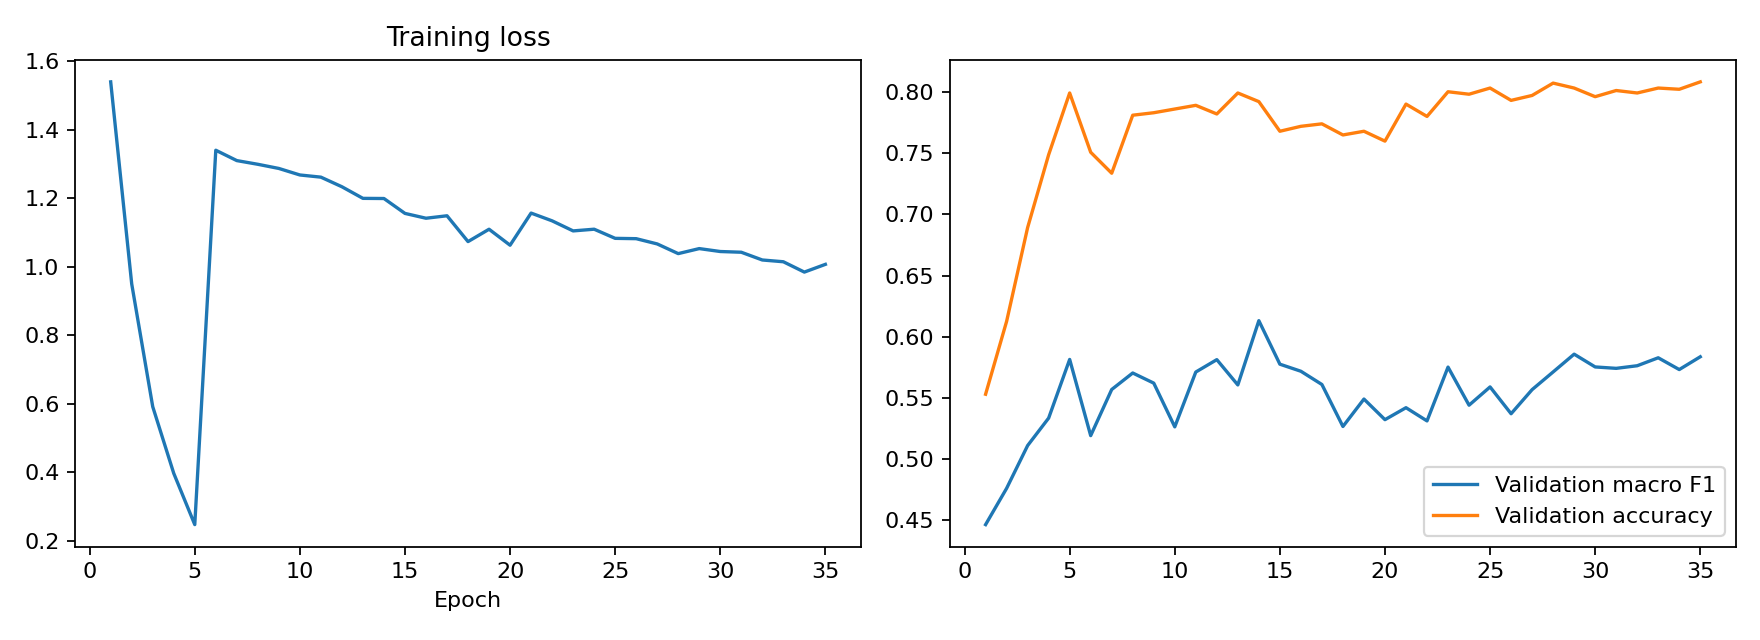

confusion_matrix.png:   0%|          | 0.00/51.2k [00:00<?, ?B/s]

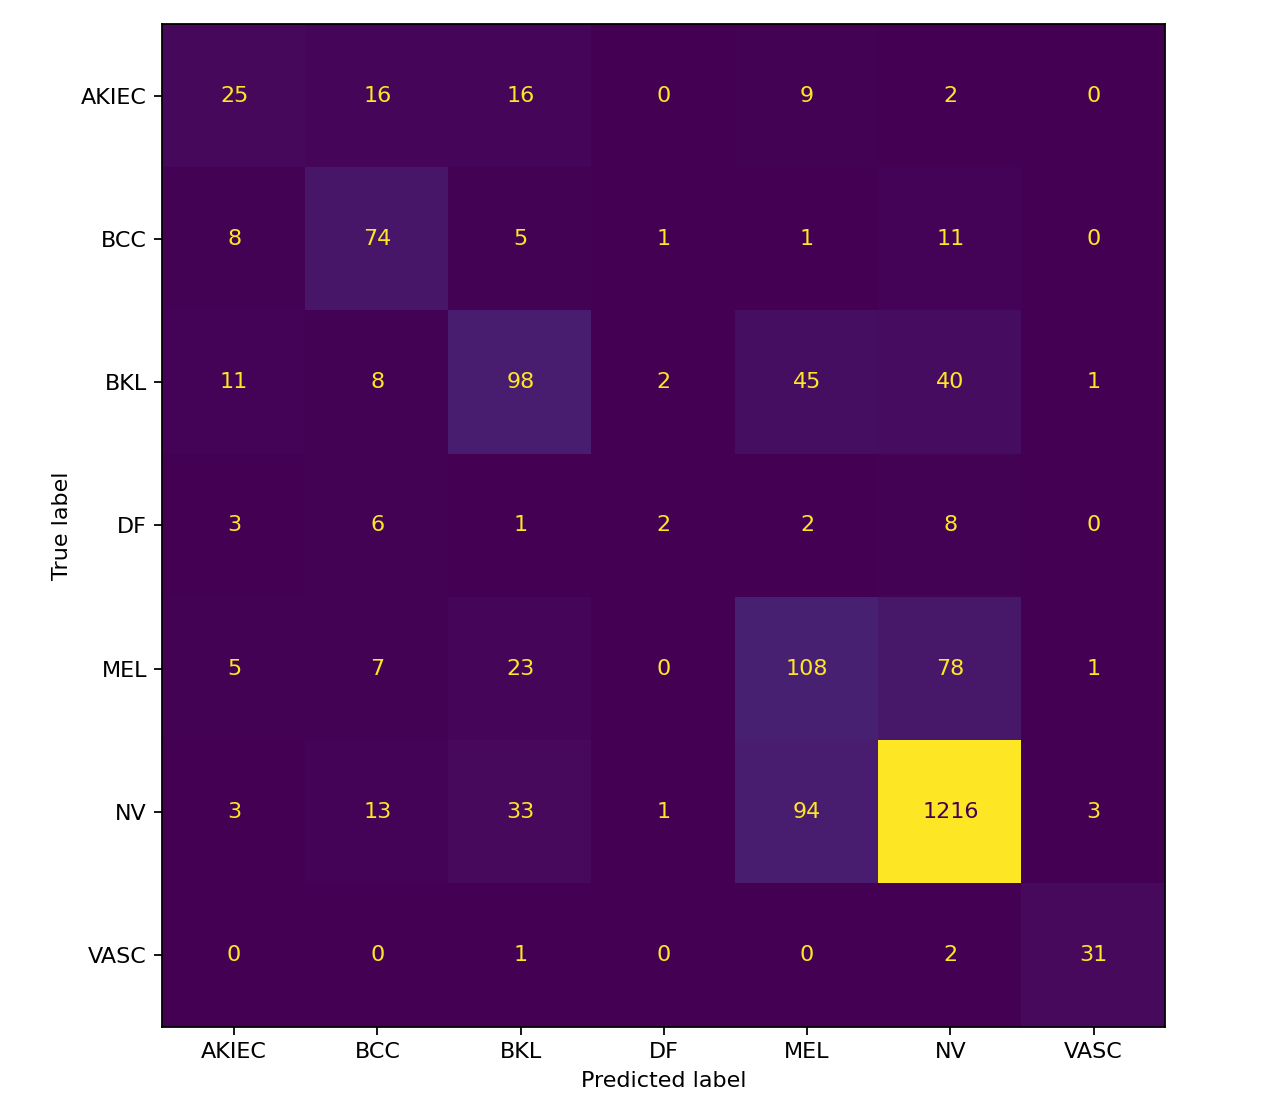

roc_curves.png:   0%|          | 0.00/97.4k [00:00<?, ?B/s]

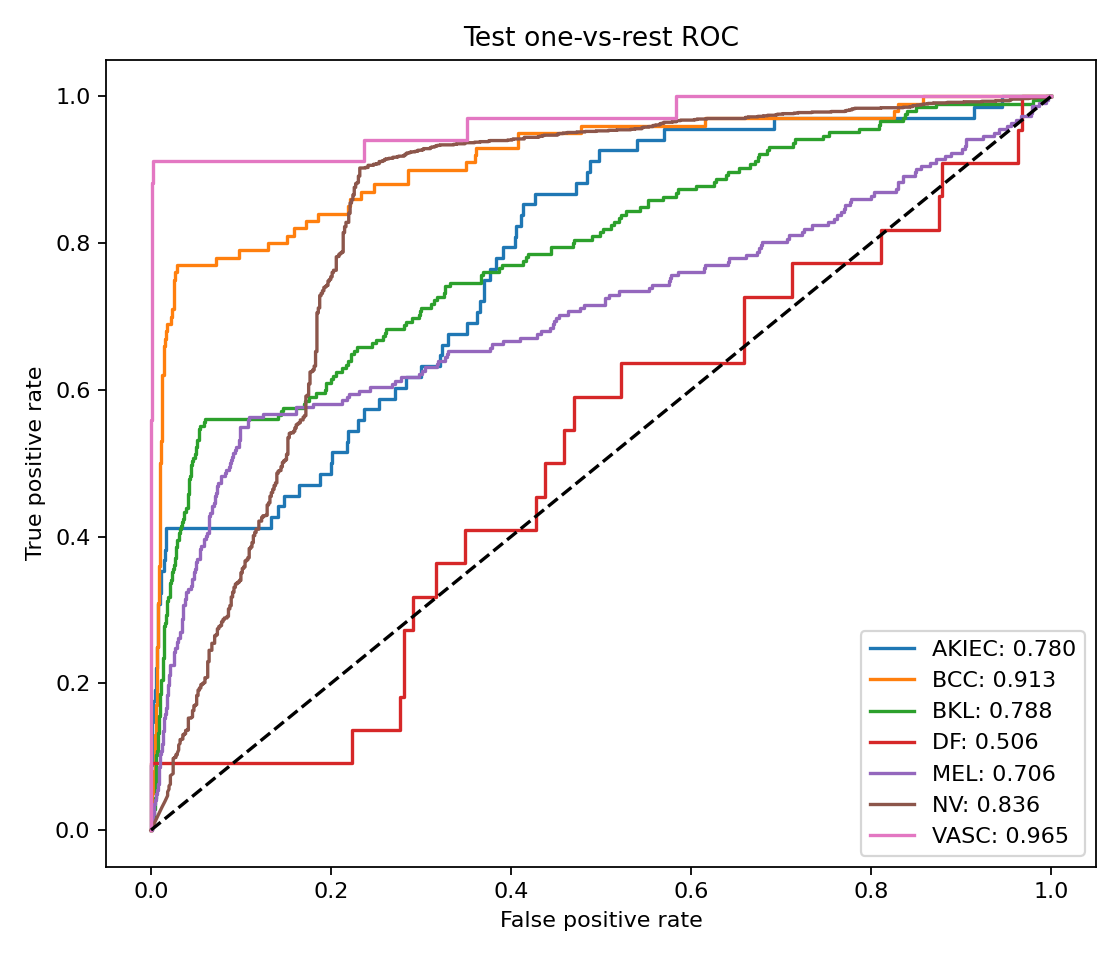

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image as DisplayImage
from huggingface_hub import HfApi, hf_hub_download
from getpass import getpass

# Load results from our improved GNAL experiment
REPO = "bigj15/gnal-training-checkpoints"
RUN_ID = "pretrained-v1-fold0-20pct"

token = None
try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass

if not token:
    token = getpass("HF token (hidden): ")

api = HfApi(token=token)
revision = api.repo_info(REPO, repo_type="model").sha
files = set(api.list_repo_files(REPO, repo_type="model", revision=revision))

out = Path("/kaggle/working/hf_results")
out.mkdir(parents=True, exist_ok=True)

def fetch(filename):
    # Prefer final results; fall back to epoch backup files.
    candidates = [
        f"{RUN_ID}/results/{filename}",
        f"{RUN_ID}/{filename}",
    ]
    for remote in candidates:
        if remote in files:
            return Path(hf_hub_download(
                repo_id=REPO,
                filename=remote,
                repo_type="model",
                revision=revision,
                token=token,
            ))
    return None

metrics_path = fetch("test_metrics.json")
if metrics_path:
    metrics = json.loads(metrics_path.read_text())
    display(pd.DataFrame(
        list(metrics.items()), columns=["Metric", "Value"]
    ))
else:
    print(
        "Final test metrics are not on HF yet. "
        "The final evaluation/upload may not have completed."
    )

report_path = fetch("classification_report.csv")
if report_path:
    display(pd.read_csv(report_path, index_col=0))

history_path = fetch("history.csv")
if history_path:
    history = pd.read_csv(history_path)
    display(history)
    print(f"Last backed-up epoch: {int(history.epoch.max())}")

for name in [
    "training_curves.png",
    "confusion_matrix.png",
    "roc_curves.png",
]:
    path = fetch(name)
    if path:
        display(DisplayImage(filename=str(path)))
    else:
        print(f"Not uploaded: {name}")

test_predictions.csv:   0%|          | 0.00/334k [00:00<?, ?B/s]

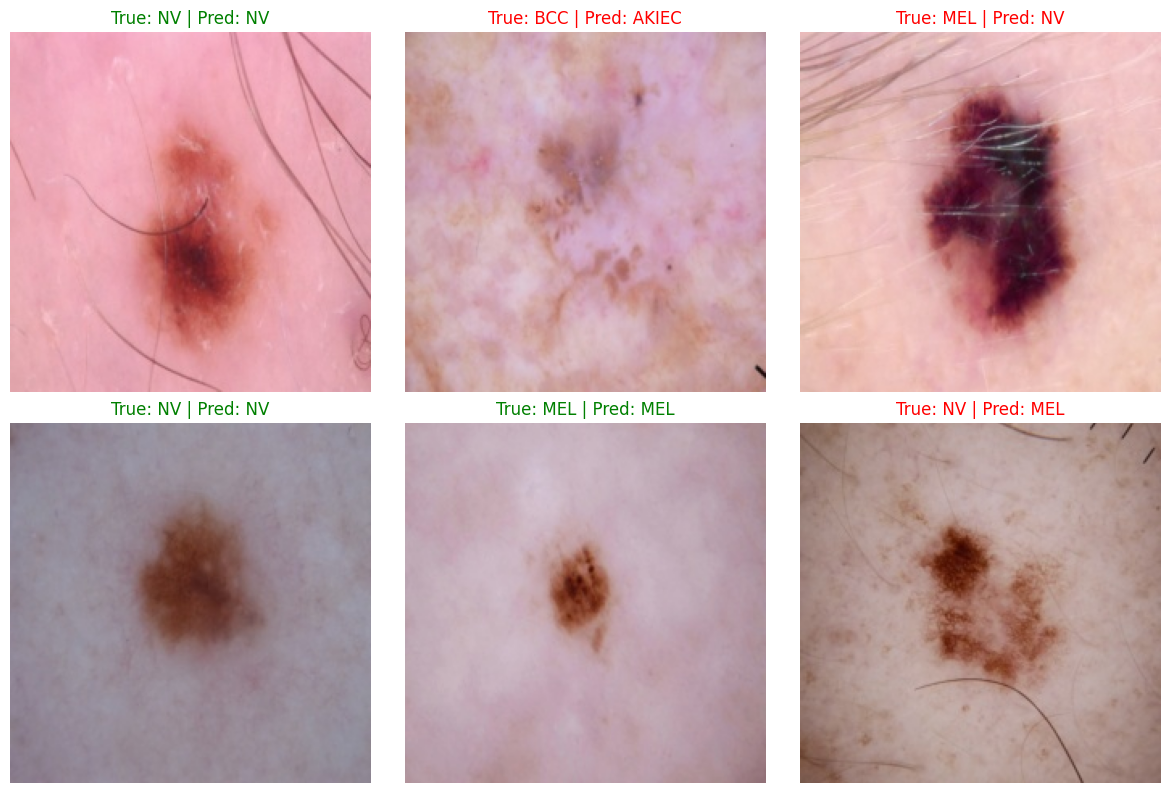

Saved: /kaggle/working/example_predictions.png


In [10]:
import io
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from datasets import load_dataset, Image as HFImage

# Uses fetch() from the previous replacement cell.
pred_path = fetch("test_predictions.csv")
if pred_path is None:
    raise FileNotFoundError(
        "Test predictions are not on HF yet. "
        "Complete the final evaluation and upload first."
    )

pred = pd.read_csv(pred_path)
if pred.empty:
    raise ValueError("The predictions file is empty.")

examples = pred.sample(n=min(6, len(pred)), random_state=42)

test_ds = load_dataset(
    "aee4/ham10000-gnal-fold0-20pct",
    revision="5b3b97348122b168f200c20352e32ac8b082c988",
    split="test",
    token=False,
).cast_column("image", HFImage(decode=False))

image_lookup = {
    image_id: index
    for index, image_id in enumerate(test_ds["image_id"])
}

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    image_id = row["image_id"]
    if image_id not in image_lookup:
        raise ValueError(f"Prediction image not found in test split: {image_id}")

    entry = test_ds[image_lookup[image_id]]["image"]
    source = (
        io.BytesIO(entry["bytes"])
        if entry.get("bytes") is not None
        else entry["path"]
    )

    with Image.open(source) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"True: {row['true_class']} | Pred: {row['predicted_class']}",
        color=(
            "green"
            if row["true_class"] == row["predicted_class"]
            else "red"
        ),
    )

for ax in axes.flat:
    ax.axis("off")

fig.tight_layout()
output_path = Path("/kaggle/working/example_predictions.png")
fig.savefig(output_path, dpi=150)
plt.show()
print("Saved:", output_path)

## Preserve the run
Save a Kaggle notebook version with outputs. The archive contains checkpoints, the pinned dataset reference, configuration, metrics and plots. Keep `last.pt`, `best.pt` and `hf_dataset_reference.json` together when resuming. The public dataset remains separate from these model outputs.

In [ ]:
import shutil
from IPython.display import FileLink
archive = shutil.make_archive('/kaggle/working/gnal_results', 'zip', root_dir=str(out))
display(FileLink(archive))
print('Also use Kaggle Save Version with outputs enabled.')


## Implementation assumptions


The paper does not provide a complete runnable specification. These are explicit decisions, not confirmed author settings:

- Original author split IDs are unavailable; Notebook 01 creates and publishes the fixed split used here. The code uses 5-fold stratified GROUP outer splitting by lesion, followed by one of 8 grouped inner folds for approximately 70/10/20 proportions. Image counts will differ from Table 1. Folds share the same fixed seed.
- Label budgets are sampled by whole lesions, stratified by diagnosis. Therefore the achieved fraction of labelled **images** is approximate. This avoids labelling one view while pretending a second view of the same lesion is unlabelled.
- Unlabelled samples are sampled uniformly. Only labelled samples use class-balanced weighted sampling; class-balancing unlabelled data using hidden diagnoses would leak labels.
- The neighbourhood cap defaults to 32; graph context is capped at 96 additional training nodes. Current sample neighbourhoods refresh each step; context neighbourhoods refresh globally once per epoch. This makes Kaggle training manageable, but is an approximation to all-sample graphs and per-iteration global updates.
- `max_neighbors=0` removes the neighbour-search cap, but the context cap still applies. Large neighbourhoods can be expensive. No profile claims uncapped full-graph replication.
- Inferred defaults: temperature 0.1, neighbour probability-ratio threshold 0.8, gamma 1.0, entropy adjustment beta 0.1, confidence threshold 0.95, labelled/unlabelled batch ratio 1, GCN hidden size 256. Temperature uses the conventional `similarity / temperature`; Eq. 3 typography is ambiguous.
- Feature normalization before graph propagation, symmetric edges, adjacency normalization/self-loops, supervised loss combination, weak augmentation recipe and RandAugment settings are implementation choices.
- Warmup jointly trains the encoder and GCN on labelled CE, while using unlabelled feature context without its labels. The LR scheduler drops by 0.1 every 20 epochs across the entire warmup + main schedule. The paper does not clearly specify the scheduler boundary behavior.
- Evaluation attaches each held-out image to its own training-only context. No validation/test images enter the reference bank, no held-out samples connect to each other, and no held-out labels enter message passing. Query edges are one-way into the query so training context is not modified by it. The paper's inference procedure is underspecified; this is our leakage-controlled inductive protocol.
- `friday` uses ImageNet weights and ImageNet normalization with a shortened schedule. `paper` uses random initialization and [0,1] image scaling. Do not combine these result rows without disclosing the difference.
- Grad-CAM and t-SNE are not included. The delivered plots are quantitative evaluation plots and example predictions.


## Honest presentation statement
“We independently implemented GNAL’s main components. Our run used [initialization], [actual labelled count], [actual epochs], and one lesion-separated fold. Our measured results were [own metrics].”

Source paper: https://doi.org/10.1016/j.bspc.2026.109886
Dataset task: https://challenge.isic-archive.com/landing/2018/47/

### Hugging Face preparation
Dataset images may already have been resized and JPEG-reencoded by Notebook 01. This is another documented preprocessing choice. Saved dataset splits and label flags are reused exactly. The Hub commit is written to `hf_dataset_reference.json`. No new labels, splits or hidden-label-based resampling are created during download.

### Verification limits
The local synthetic data, image-byte round trip, split isolation and CPU training path were tested. A real authenticated Hub upload and Kaggle CUDA training must be tested by running these notebooks; no upload has been performed on your behalf.
